# Monitorización de una máquina CNC industrial

## Análisis exploratorio de variables operativas y mediciones de sensores

### 1. Introducción

Este proyecto se centra en el análisis exploratorio de datos de una máquina CNC industrial.

El objetivo es comprender el comportamiento operativo y térmico de la máquina mediante la combinación de dos fuentes de datos: las variables operativas del CNC y las mediciones de diferentes sensores.

### 2. Descripción de los conjuntos de datos

El análisis utiliza dos conjuntos de datos en formato Excel:

- **CNCVariables:** variables operativas de la máquina, incluyendo cargas de los ejes, velocidades, posiciones, potencia, intensidad y temperaturas.

### SensorData

Conjunto de datos compuesto por 65 columnas y 89.393 registros, procedentes de sensores externos instalados en la máquina CNC.

Incluye dos grupos de mediciones:

- **Sensores IDS (Bar_01 a Bar_14):** 14 canales que miden deformaciones estructurales inducidas térmicamente, expresadas en micrómetros (µm).
- **Termopares (Thermocouple_01 a Thermocouple_49):** 49 canales que registran temperaturas en diferentes componentes y zonas de la máquina, expresadas en grados Celsius (°C).

La adquisición se realizó entre el 6 y el 8 de noviembre de 2024, con una frecuencia nominal de 1 Hz y periodos no continuos de registro.


En conjunto, ambos archivos contienen 179.048 registros y 106 columnas.

### 3. Objetivo del análisis

Comprender el comportamiento operativo y térmico de la máquina CNC, identificar patrones estadísticos y explorar posibles relaciones entre las condiciones de funcionamiento de la máquina y las mediciones de los sensores.

### 4. Preguntas de investigación

- **PI01:** ¿Cómo se comporta la máquina CNC durante el periodo de observación?
- **PI02:** ¿Qué diferencias existen entre las mediciones de temperatura de los distintos termopares?
- **PI03:** ¿Existe una relación entre las cargas de los ejes y las variaciones de temperatura?
- **PI04:** ¿Está relacionada la velocidad del husillo con el comportamiento térmico de la máquina?
- **PI05:** ¿Se pueden identificar patrones de calentamiento y enfriamiento?
- **PI06:** ¿Es posible identificar condiciones de funcionamiento estadísticamente inusuales?

### 5. Metodología

1. Comprensión de los datos.
2. Evaluación y limpieza de los datos.
3. Análisis univariante.
4. Análisis bivariante y multivariante.
5. Ingeniería de características (*Feature Engineering*).
6. Análisis de series temporales.
7. Exploración de anomalías.
8. Conclusiones.

### 6. Limitaciones

- No se dispone de etiquetas confirmadas de fallos o averías.
- No está documentada la ubicación física de los sensores.
- El significado de los canales Bar y sus unidades de medida requieren verificación.
- La correlación entre variables no implica causalidad.
- El modelado predictivo queda fuera del alcance inicial de este análisis exploratorio.


In [3]:
# Importamos las librerías necesarias

import pandas as pd
import numpy as np

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)


In [4]:
# Rutas de los archivos originales
ruta_cnc = "https://zenodo.org/records/16579804/files/CNCVariables6to8November2024.xlsx?download=1"
ruta_sensores = "https://zenodo.org/records/16579804/files/SensorData6To8November2024.xlsx?download=1"

# Lectura de los archivos Excel
cnc = pd.read_excel(ruta_cnc)
sensores = pd.read_excel(ruta_sensores)

In [5]:
# Comprobamos el número de filas y columnas

print("DIMENSIONES DE LOS DATASETS")

print(f"CNCVariables: {cnc.shape}")
print(f"SensorData: {sensores.shape}")

DIMENSIONES DE LOS DATASETS
CNCVariables: (89655, 41)
SensorData: (89393, 65)


In [6]:
# Visualizamos las primeras cinco filas
display(cnc.head())
display(sensores.head())

,Date,Timestamp,AAxisIntensity,AAxisLoad,AAxisPositionActual,AAxisPower,AAxisSpeed,CAxisIntensity,CAxisLoad,CAxisPositionActual,CAxisPower,CAxisSpeed,CAxisTemperature,ControllerMode,ExecutionState,PathFeedrateActual,PathFeedrateOverride,SPActualSpeed,SPAxisIntensity,SPAxisLoad,SPAxisPower,SPAxisTemperature,SpindleOverride,XAxisIntensity,XAxisLoad,XAxisPositionActual,XAxisPower,XAxisSpeed,XAxisTemperature,YAxisIntensity,YAxisLoad,YAxisPositionActual,YAxisPower,YAxisSpeed,YAxisTemperature,ZAxisIntensity,ZAxisLoad,ZAxisPositionActual,ZAxisPower,ZAxisSpeed,ZAxisTemperature
0,2024-11-06 06:47:47.362,1730875667.362,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,0.000,24.052,100,0.000,0.000,-0.000,-0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,-0.000,0.000,19.580
1,2024-11-06 06:47:48.362,1730875668.362,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,0.000,24.052,100,0.000,0.000,-0.000,-0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,-0.000,0.000,19.580
2,2024-11-06 06:47:49.363,1730875669.363,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,-0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,0.000,24.052,100,0.000,0.000,-0.000,0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,0.000,0.000,19.558
3,2024-11-06 06:47:50.362,1730875670.362,0.004,0.000,0.000,0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,-0.000,24.064,100,0.000,0.000,-0.000,0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,0.000,0.000,19.558
4,2024-11-06 06:47:51.362,1730875671.362,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,-0.000,24.026,100,0.000,0.000,-0.000,0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,0.000,0.000,19.599


,Date,Timestamp,Bar_01,Bar_02,Bar_03,Bar_04,Bar_05,Bar_06,Bar_07,Bar_08,Bar_09,Bar_10,Bar_11,Bar_12,Bar_13,Bar_14,Thermocouple_01,Thermocouple_02,Thermocouple_03,Thermocouple_04,Thermocouple_05,Thermocouple_06,Thermocouple_07,Thermocouple_08,Thermocouple_09,Thermocouple_10,Thermocouple_11,Thermocouple_12,Thermocouple_13,Thermocouple_14,Thermocouple_15,Thermocouple_16,Thermocouple_17,Thermocouple_18,Thermocouple_19,Thermocouple_20,Thermocouple_21,Thermocouple_22,Thermocouple_23,Thermocouple_24,Thermocouple_25,Thermocouple_26,Thermocouple_27,Thermocouple_28,Thermocouple_29,Thermocouple_30,Thermocouple_31,Thermocouple_32,Thermocouple_33,Thermocouple_34,Thermocouple_35,Thermocouple_36,Thermocouple_37,Thermocouple_38,Thermocouple_39,Thermocouple_40,Thermocouple_41,Thermocouple_42,Thermocouple_43,Thermocouple_44,Thermocouple_45,Thermocouple_46,Thermocouple_47,Thermocouple_48,Thermocouple_49
0,2024-11-06 06:50:07,1730875807,58962.570,61182.460,60312.920,58430.210,63274.950,61873.820,58747.520,60691.690,59931.140,61356.850,58127.300,59703.950,60970.130,58614.510,18.700,17.800,16.900,17.800,17.900,19.100,18.100,16.100,18.600,17.400,16.900,17.800,17.800,18.600,17.800,16.100,18.600,17.700,16.900,18.100,17.800,19.000,18.000,16.100,18.600,17.400,16.500,17.400,17.400,18.500,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.800,14.800,16.800
1,2024-11-06 06:50:08,1730875808,58962.590,61182.440,60312.950,58430.260,63274.950,61873.890,58747.470,60691.730,59931.170,61356.800,58127.260,59704.000,60970.170,58614.540,18.700,17.800,16.900,17.800,17.900,19.200,18.100,16.100,18.600,17.400,16.800,17.800,17.800,18.600,17.800,16.100,18.600,17.700,16.900,18.100,17.800,19.000,18.100,16.100,18.600,17.400,16.600,17.400,17.400,18.600,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.700,14.800,16.800
2,2024-11-06 06:50:09,1730875809,58962.620,61182.460,60312.950,58430.260,63275.020,61873.840,58747.500,60691.730,59931.140,61356.800,58127.260,59703.950,60970.170,58614.560,18.700,17.800,16.900,17.800,17.900,19.100,18.100,16.100,18.600,17.400,16.900,17.800,17.800,18.600,17.800,16.100,18.600,17.700,16.900,18.100,17.800,19.000,18.100,16.100,18.600,17.400,16.600,17.400,17.400,18.500,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.700,14.800,16.800
3,2024-11-06 06:50:10,1730875810,58962.570,61182.460,60312.920,58430.230,63274.950,61873.890,58747.500,60691.690,59931.120,61356.850,58127.300,59703.950,60970.170,58614.510,18.700,17.800,16.900,17.900,17.900,19.100,18.100,16.100,18.600,17.400,16.800,17.800,17.800,18.600,17.800,16.100,18.600,17.800,16.900,18.100,17.800,19.000,18.100,16.200,18.600,17.400,16.600,17.400,17.400,18.600,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.800,14.800,16.800
4,2024-11-06 06:50:11,1730875811,58962.640,61182.510,60312.920,58430.210,63274.980,61873.840,58747.450,60691.730,59931.190,61356.820,58127.300,59704.000,60970.150,58614.510,18.700,17.800,16.900,17.800,17.900,19.200,18.100,16.100,18.600,17.400,16.900,17.800,17.800,18.600,17.800,16.100,18.600,17.800,16.900,18.100,17.800,19.000,18.000,16.200,18.600,17.400,16.600,17.400,17.400,18.600,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.900,16.700,14.800,16.700


In [7]:
# Comprobamos los tipos de datos de cada columna

print("Tipos de datos de CNCVariables:")
print(cnc.dtypes)

print("\nTipos de datos de SensorData:")
print(sensores.dtypes)

Tipos de datos de CNCVariables:
Date                    datetime64[us]
Timestamp                      float64
AAxisIntensity                 float64
AAxisLoad                      float64
AAxisPositionActual            float64
AAxisPower                     float64
AAxisSpeed                     float64
CAxisIntensity                 float64
CAxisLoad                      float64
CAxisPositionActual            float64
CAxisPower                     float64
CAxisSpeed                     float64
CAxisTemperature               float64
ControllerMode                   int64
ExecutionState                   int64
PathFeedrateActual             float64
PathFeedrateOverride           float64
SPActualSpeed                  float64
SPAxisIntensity                float64
SPAxisLoad                     float64
SPAxisPower                    float64
SPAxisTemperature              float64
SpindleOverride                  int64
XAxisIntensity                 float64
XAxisLoad                      f

In [8]:
# Contamos cuántas columnas hay de cada tipo

print("CNCVariables:")
print(cnc.dtypes.value_counts())

print("\nSensorData:")
print(sensores.dtypes.value_counts())

CNCVariables:
float64           37
int64              3
datetime64[us]     1
Name: count, dtype: int64

SensorData:
float64           63
datetime64[us]     1
int64              1
Name: count, dtype: int64


In [9]:
# Información general de CNCVariables
print("INFORMACIÓN DE CNCVariables")
cnc.info()

# Información general de SensorData
print("\nINFORMACIÓN DE SensorData")
sensores.info()

INFORMACIÓN DE CNCVariables
<class 'pandas.DataFrame'>
RangeIndex: 89655 entries, 0 to 89654
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  89655 non-null  datetime64[us]
 1   Timestamp             89655 non-null  float64       
 2   AAxisIntensity        89655 non-null  float64       
 3   AAxisLoad             89655 non-null  float64       
 4   AAxisPositionActual   89655 non-null  float64       
 5   AAxisPower            89655 non-null  float64       
 6   AAxisSpeed            89655 non-null  float64       
 7   CAxisIntensity        89655 non-null  float64       
 8   CAxisLoad             89655 non-null  float64       
 9   CAxisPositionActual   89655 non-null  float64       
 10  CAxisPower            89655 non-null  float64       
 11  CAxisSpeed            89655 non-null  float64       
 12  CAxisTemperature      89655 non-null  float64       
 13 

### Observaciones iniciales

Tras inspeccionar ambos conjuntos de datos se observa:

- CNCVariables contiene 89.655 registros y 41 columnas.
- SensorData contiene 89.393 registros y 65 columnas.
- Ambos conjuntos presentan el 100 % de valores no nulos.
- Las variables de medición son de tipo numérico.
- Ambos conjuntos contienen una variable temporal denominada Date.
- Timestamp presenta diferentes tipos de datos en cada conjunto.

La ausencia de valores nulos no garantiza la calidad de las mediciones.
Será necesario investigar posibles valores anómalos, duplicados,
inconsistencias y errores de adquisición.

In [10]:
# Comprobamos los valores diferentes de las variables enteras
print("ControllerMode:")
print(cnc["ControllerMode"].unique())
print("\nExecutionState:")
print(cnc["ExecutionState"].unique())
print("\nSpindleOverride:")
print(cnc["SpindleOverride"].unique())

ControllerMode:
[0 2 1]

ExecutionState:
[5 2 3 1]

SpindleOverride:
[100]


In [11]:
# Frecuencia de los valores de cada variable
print("Distribución de ControllerMode:")
print(cnc["ControllerMode"].value_counts().sort_index())
print("\nDistribución de ExecutionState:")
print(cnc["ExecutionState"].value_counts().sort_index())
print("\nDistribución de SpindleOverride:")
print(cnc["SpindleOverride"].value_counts().sort_index())

Distribución de ControllerMode:
ControllerMode
0    25083
1      397
2    64175
Name: count, dtype: int64

Distribución de ExecutionState:
ExecutionState
1     2575
2     4750
3    45080
5    37250
Name: count, dtype: int64

Distribución de SpindleOverride:
SpindleOverride
100    89655
Name: count, dtype: int64


### Análisis inicial de variables de estado

Se han identificado tres variables enteras en CNCVariables:

- ControllerMode presenta tres valores (0, 1 y 2). El valor 2 representa el 71,59 % de los registros.
- ExecutionState presenta cuatro valores (1, 2, 3 y 5). Los estados 3 y 5 concentran el 91,83 % de los registros.
- SpindleOverride mantiene un valor constante de 100 durante todo el periodo.

Los significados de ControllerMode y ExecutionState están pendientes de verificación mediante documentación técnica.

SpindleOverride no presenta variabilidad y, por tanto, no permitirá estudiar relaciones estadísticas basadas en cambios de esta variable.

In [12]:
# Comprobamos la fecha de inicio y finalización de cada dataset
print("PERIODO CNCVariables")
print("Inicio:", cnc["Date"].min())
print("Final:", cnc["Date"].max())
print("\nPERIODO SensorData")
print("Inicio:", sensores["Date"].min())
print("Final:", sensores["Date"].max())

PERIODO CNCVariables
Inicio: 2024-11-06 06:47:47.362000
Final: 2024-11-08 13:41:58.388000

PERIODO SensorData
Inicio: 2024-11-06 06:50:07
Final: 2024-11-08 13:42:47


In [13]:
# Analizamos los valores temporales de ambos datasets
print("Timestamp CNCVariables")
print("Mínimo:", cnc["Timestamp"].min())
print("Máximo:", cnc["Timestamp"].max())
print("Valores diferentes:", cnc["Timestamp"].nunique())

print("\nTimestamp SensorData")
print("Mínimo:", sensores["Timestamp"].min())
print("Máximo:", sensores["Timestamp"].max())
print("Valores diferentes:", sensores["Timestamp"].nunique())

Timestamp CNCVariables
Mínimo: 1730875667.3620002
Máximo: 1731073318.3880002
Valores diferentes: 89655

Timestamp SensorData
Mínimo: 1730875807
Máximo: 1731073367
Valores diferentes: 89389


In [14]:
# Check sampling frequency

cnc["Date"] = pd.to_datetime(cnc["Date"])
sensors["Date"] = pd.to_datetime(sensors["Date"])

print("CNC sampling intervals:")
print(cnc["Date"].diff().value_counts().head())

print("\nSensor sampling intervals:")
print(sensors["Date"].diff().value_counts().head())

NameError: name 'sensors' is not defined

### Análisis temporal inicial

Ambos conjuntos presentan una frecuencia de adquisición cercana a un registro por segundo.

Se han identificado las siguientes características:

- CNCVariables contiene 89.655 timestamps diferentes.
- SensorData contiene 89.389 timestamps diferentes.
- SensorData presenta cuatro timestamps duplicados, correspondientes a ocho registros.
- Los registros duplicados contienen mediciones diferentes.
- Ambos conjuntos presentan dos grandes interrupciones temporales entre jornadas de adquisición.
- Las fechas y los timestamps deben estudiarse teniendo en cuenta sus diferentes precisiones.

Las interrupciones parecen coincidir con los cambios de jornada de los ensayos, aunque esta interpretación está pendiente de confirmación documental.

No se eliminarán registros duplicados ni se tratarán las interrupciones como errores sin investigar previamente su origen.

In [ ]:
# Buscamos los timestamps que aparecen más de una vez
duplicados = sensores[
    sensores["Timestamp"].duplicated(keep=False)
]

print("Registros con timestamps duplicados:")
print(duplicados[["Date", "Timestamp"]])

Registros con timestamps duplicados:
                     Date   Timestamp
81466 2024-11-08 11:30:41  1731065441
81467 2024-11-08 11:30:41  1731065441
81475 2024-11-08 11:30:50  1731065450
81476 2024-11-08 11:30:50  1731065450
81549 2024-11-08 11:32:04  1731065524
81550 2024-11-08 11:32:04  1731065524
81555 2024-11-08 11:32:10  1731065530
81556 2024-11-08 11:32:10  1731065530


In [ ]:
# Comprobamos si las filas duplicadas contienen las mismas mediciones

print("Número de filas duplicadas:")
print(len(duplicados))

print("\nNúmero de filas completamente iguales:")
print(duplicados.duplicated().sum())

Número de filas duplicadas:
8

Número de filas completamente iguales:
0


In [ ]:
# Seleccionamos las columnas de medición
columnas_medicion = sensores.columns.drop(["Date", "Timestamp"])

# Comprobamos cuántos valores diferentes tiene cada sensor
# dentro de cada grupo de timestamps duplicados
diferencias = duplicados.groupby("Timestamp")[columnas_medicion].nunique()

# Mostramos los sensores que presentan diferencias
for timestamp in diferencias.index:

    columnas_diferentes = diferencias.columns[
        diferencias.loc[timestamp] > 1
    ]

    print("\nTimestamp:", timestamp)
    print("Sensores diferentes:", len(columnas_diferentes))
    print(list(columnas_diferentes))


Timestamp: 1731065441
Sensores diferentes: 13
['Bar_01', 'Bar_02', 'Bar_03', 'Bar_04', 'Bar_06', 'Bar_07', 'Bar_10', 'Bar_12', 'Thermocouple_06', 'Thermocouple_07', 'Thermocouple_12', 'Thermocouple_20', 'Thermocouple_37']

Timestamp: 1731065450
Sensores diferentes: 14
['Bar_01', 'Bar_02', 'Bar_03', 'Bar_05', 'Bar_06', 'Bar_07', 'Bar_09', 'Bar_10', 'Bar_11', 'Bar_12', 'Bar_14', 'Thermocouple_14', 'Thermocouple_37', 'Thermocouple_39']

Timestamp: 1731065524
Sensores diferentes: 11
['Bar_02', 'Bar_03', 'Bar_05', 'Bar_06', 'Bar_08', 'Bar_10', 'Bar_11', 'Bar_14', 'Thermocouple_01', 'Thermocouple_02', 'Thermocouple_05']

Timestamp: 1731065530
Sensores diferentes: 14
['Bar_02', 'Bar_03', 'Bar_04', 'Bar_05', 'Bar_06', 'Bar_07', 'Bar_08', 'Bar_11', 'Bar_13', 'Bar_14', 'Thermocouple_12', 'Thermocouple_44', 'Thermocouple_46', 'Thermocouple_47']


In [ ]:
# Seleccionamos uno de los timestamps duplicados
timestamp_ejemplo = 1731065441

# Recuperamos las dos filas correspondientes
grupo = sensores[
    sensores["Timestamp"] == timestamp_ejemplo
]

# Mostramos las mediciones de ambas filas
print("Comparación de las dos mediciones:")
print(grupo.T)

Comparación de las dos mediciones:
                               81466                81467
Date             2024-11-08 11:30:41  2024-11-08 11:30:41
Timestamp                 1731065441           1731065441
Bar_01                     58880.320            58880.300
Bar_02                     61128.550            61128.570
Bar_03                     60269.130            60269.110
Bar_04                     58385.270            58385.290
Bar_05                     63115.890            63115.890
Bar_06                     61866.370            61866.340
Bar_07                     58731.630            58731.740
Bar_08                     60664.250            60664.250
Bar_09                     59868.820            59868.820
Bar_10                     61357.170            61357.190
Bar_11                     58123.780            58123.780
Bar_12                     59696.130            59696.090
Bar_13                     60963.040            60963.040
Bar_14                     58594.390 

In [ ]:
# Calculamos las diferencias entre las dos mediciones

diferencias = grupo.iloc[1][columnas_medicion] - grupo.iloc[0][columnas_medicion]

print("Diferencias entre las dos mediciones:")
print(diferencias[diferencias != 0])

Diferencias entre las dos mediciones:
Bar_01            -0.020
Bar_02             0.020
Bar_03            -0.020
Bar_04             0.020
Bar_06            -0.030
Bar_07             0.110
Bar_10             0.020
Bar_12            -0.040
Thermocouple_06   -0.100
Thermocouple_07   -0.100
Thermocouple_12    0.100
Thermocouple_20   -0.100
Thermocouple_37   -0.100
dtype: object


### Investigación de timestamps duplicados

Se han identificado cuatro timestamps duplicados en SensorData,
con dos registros para cada instante.

La comparación de las mediciones demuestra que:

- Ninguna de las ocho filas es completamente idéntica.
- Entre 11 y 14 sensores presentan diferencias en cada grupo.
- Los cambios observados son pequeños en relación con los valores registrados.
- La columna Date no permite distinguir las mediciones porque ambas
  comparten la misma precisión temporal de un segundo.

Estos resultados sugieren que podrían existir adquisiciones diferentes
dentro de un mismo segundo o algún mecanismo de duplicación temporal.

No se eliminan registros ni se agregan mediciones en esta fase.
Se mantiene la información original para investigaciones posteriores.

In [ ]:
# Comprobamos la relación entre Date y Timestamp en CNCVariables

print("CNCVariables:")
print(cnc[["Date", "Timestamp"]].head())

print("\nSensorData:")
print(sensores[["Date", "Timestamp"]].head())

CNCVariables:
                     Date      Timestamp
0 2024-11-06 06:47:47.362 1730875667.362
1 2024-11-06 06:47:48.362 1730875668.362
2 2024-11-06 06:47:49.363 1730875669.363
3 2024-11-06 06:47:50.362 1730875670.362
4 2024-11-06 06:47:51.362 1730875671.362

SensorData:
                 Date   Timestamp
0 2024-11-06 06:50:07  1730875807
1 2024-11-06 06:50:08  1730875808
2 2024-11-06 06:50:09  1730875809
3 2024-11-06 06:50:10  1730875810
4 2024-11-06 06:50:11  1730875811


In [ ]:
# Convertimos Timestamp a fecha utilizando Unix

fecha_cnc = pd.to_datetime(cnc["Timestamp"], unit="s")
fecha_sensores = pd.to_datetime(sensores["Timestamp"], unit="s")

# Comparamos las fechas calculadas con las originales

print("Diferencia en CNCVariables:")
print((cnc["Date"] - fecha_cnc).head())

print("\nDiferencia en SensorData:")
print((sensores["Date"] - fecha_sensores).head())

Diferencia en CNCVariables:
0   -1 days +23:59:59.999999773
1     0 days 00:00:00.000000250
2   -1 days +23:59:59.999999846
3   -1 days +23:59:59.999999773
4     0 days 00:00:00.000000011
dtype: timedelta64[ns]

Diferencia en SensorData:
0   0 days
1   0 days
2   0 days
3   0 days
4   0 days
dtype: timedelta64[us]


In [ ]:
# Calculamos el tiempo transcurrido entre registros consecutivos

intervalos_cnc = cnc["Date"].diff().dt.total_seconds()
intervalos_sensores = sensores["Date"].diff().dt.total_seconds()

print("Intervalos CNCVariables:")
print(intervalos_cnc.value_counts().sort_index())

print("\nIntervalos SensorData:")
print(intervalos_sensores.value_counts().sort_index())

Intervalos CNCVariables:
Date
0.931            1
0.932            1
0.955            1
0.956            1
0.974            1
0.979            1
0.987            1
0.989            1
0.990            1
0.991            5
0.992            6
0.993           11
0.994           18
0.995           22
0.996           38
0.997           57
0.998           87
0.999         5184
1.000        78571
1.001         5201
1.002           80
1.003           62
1.004           35
1.005           20
1.006           18
1.007           12
1.008            8
1.009            3
1.010            1
1.011            1
1.013            1
1.014            3
1.015            6
1.016           21
1.017           33
1.018           32
1.019           23
1.020            8
1.021            4
1.022            2
1.027            1
1.029            1
1.030            1
1.031            5
1.032           10
1.033           18
1.034           24
1.035            5
1.036            1
1.044            1
1.045            1
1

In [ ]:
# Localizamos intervalos superiores a 60 segundos

saltos_cnc = intervalos_cnc[intervalos_cnc > 60]
saltos_sensores = intervalos_sensores[intervalos_sensores > 60]

print("GRANDES INTERRUPCIONES EN CNCVariables")

for indice in saltos_cnc.index:
    print("\nRegistro anterior:")
    print(cnc.loc[indice - 1, ["Date", "Timestamp"]])

    print("Registro posterior:")
    print(cnc.loc[indice, ["Date", "Timestamp"]])

    print("Duración del intervalo:", intervalos_cnc.loc[indice], "segundos")


print("\nGRANDES INTERRUPCIONES EN SensorData")

for indice in saltos_sensores.index:
    print("\nRegistro anterior:")
    print(sensores.loc[indice - 1, ["Date", "Timestamp"]])

    print("Registro posterior:")
    print(sensores.loc[indice, ["Date", "Timestamp"]])

    print("Duración del intervalo:", intervalos_sensores.loc[indice], "segundos")

GRANDES INTERRUPCIONES EN CNCVariables

Registro anterior:
Date         2024-11-06 15:52:26.986000
Timestamp                1730908346.986
Name: 32678, dtype: object
Registro posterior:
Date         2024-11-07 06:46:11.529000
Timestamp                1730961971.529
Name: 32679, dtype: object
Duración del intervalo: 53624.543 segundos

Registro anterior:
Date         2024-11-07 15:49:13.156000
Timestamp                1730994553.156
Name: 65259, dtype: object
Registro posterior:
Date         2024-11-08 06:55:23.173000
Timestamp                1731048923.173
Name: 65260, dtype: object
Duración del intervalo: 54370.017 segundos

GRANDES INTERRUPCIONES EN SensorData

Registro anterior:
Date         2024-11-06 15:53:35
Timestamp             1730908415
Name: 32605, dtype: object
Registro posterior:
Date         2024-11-07 06:48:13
Timestamp             1730962093
Name: 32606, dtype: object
Duración del intervalo: 53678.0 segundos

Registro anterior:
Date         2024-11-07 15:50:12
Timestamp

In [ ]:
# Obtenemos el inicio y el final de cada conjunto de datos
inicio_cnc = cnc["Date"].min()
fin_cnc = cnc["Date"].max()

inicio_sensores = sensores["Date"].min()
fin_sensores = sensores["Date"].max()

# Calculamos el periodo común
inicio_comun = max(inicio_cnc, inicio_sensores)
fin_comun = min(fin_cnc, fin_sensores)

print("COBERTURA CNCVariables")
print("Inicio:", inicio_cnc)
print("Final:", fin_cnc)

print("\nCOBERTURA SensorData")
print("Inicio:", inicio_sensores)
print("Final:", fin_sensores)

print("\nPERIODO COMÚN")
print("Inicio:", inicio_comun)
print("Final:", fin_comun)

print(
    "Duración del periodo común:",
    fin_comun - inicio_comun
)

COBERTURA CNCVariables
Inicio: 2024-11-06 06:47:47.362000
Final: 2024-11-08 13:41:58.388000

COBERTURA SensorData
Inicio: 2024-11-06 06:50:07
Final: 2024-11-08 13:42:47

PERIODO COMÚN
Inicio: 2024-11-06 06:50:07
Final: 2024-11-08 13:41:58.388000
Duración del periodo común: 2 days 06:51:51.388000


In [ ]:
# Comprobamos qué registros pertenecen al periodo común

cnc_comun = cnc[
    (cnc["Date"] >= inicio_comun) &
    (cnc["Date"] <= fin_comun)
]

sensores_comun = sensores[
    (sensores["Date"] >= inicio_comun) &
    (sensores["Date"] <= fin_comun)
]

print("CNCVariables")
print("Registros totales:", len(cnc))
print("Registros dentro del periodo común:", len(cnc_comun))
print("Registros fuera del periodo común:", len(cnc) - len(cnc_comun))

print("\nSensorData")
print("Registros totales:", len(sensores))
print("Registros dentro del periodo común:", len(sensores_comun))
print("Registros fuera del periodo común:", len(sensores) - len(sensores_comun))

CNCVariables
Registros totales: 89655
Registros dentro del periodo común: 89515
Registros fuera del periodo común: 140

SensorData
Registros totales: 89393
Registros dentro del periodo común: 89344
Registros fuera del periodo común: 49


In [ ]:
# Resumen estadístico de las variables numéricas del CNC

cnc.describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
Date,2024-11-06 06:47:47.362000,2024-11-08 13:41:58.388000,2024-11-07 08:49:28.229952,NaN
Timestamp,1730875667.362,1731073318.388,1730969368.230,67668.114
AAxisIntensity,0.000,35.998,0.066,0.797
AAxisLoad,0.000,43.758,0.180,2.126
AAxisPositionActual,-135.000,30.000,-51.345,45.029
AAxisPower,-0.124,0.960,0.000,0.010
AAxisSpeed,-7200.000,5000.000,0.175,87.835
CAxisIntensity,0.000,50.302,0.584,0.673
CAxisLoad,0.000,9.130,0.207,0.224
CAxisPositionActual,0.000,360.000,154.408,120.545


In [ ]:
# Resumen estadístico de las mediciones de los sensores

sensores.describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
Date,2024-11-06 06:50:07,2024-11-08 13:42:47,2024-11-07 08:49:57.705122,NaN
Timestamp,1730875807.000,1731073367.000,1730969397.705,67641.085
Bar_01,58820.200,58967.590,58904.206,37.532
Bar_02,61091.540,61186.390,61143.249,27.039
Bar_03,60251.140,60314.070,60284.007,19.100
Bar_04,58359.460,58433.040,58399.072,19.914
Bar_05,63110.070,63281.630,63205.964,67.082
Bar_06,61862.340,61892.010,61876.094,9.010
Bar_07,58723.050,58749.220,58737.599,7.127
Bar_08,60650.430,60692.010,60671.224,11.746


In [15]:
# Agrupamos los sensores por tipo de medición

subset_ids = sensores[
    [col for col in sensores.columns if col.startswith("Bar_")]
]

subset_termopares = sensores[
    [col for col in sensores.columns if col.startswith("Thermocouple_")]
]

print("Sensores IDS:", subset_ids.shape[1])
print("Termopares:", subset_termopares.shape[1])

Sensores IDS: 14
Termopares: 49


In [16]:
# Agrupamos las variables de cada eje

subset_x = cnc.filter(regex="^XAxis")
subset_y = cnc.filter(regex="^YAxis")
subset_z = cnc.filter(regex="^ZAxis")
subset_a = cnc.filter(regex="^AAxis")
subset_c = cnc.filter(regex="^CAxis")

print("Eje X:", subset_x.shape[1], "variables")
print("Eje Y:", subset_y.shape[1], "variables")
print("Eje Z:", subset_z.shape[1], "variables")
print("Eje A:", subset_a.shape[1], "variables")
print("Eje C:", subset_c.shape[1], "variables")

Eje X: 6 variables
Eje Y: 6 variables
Eje Z: 6 variables
Eje A: 5 variables
Eje C: 6 variables


In [18]:
# Agrupamos las variables relacionadas con el husillo

subset_husillo = cnc[
    [
        "SPActualSpeed",
        "SPAxisIntensity",
        "SPAxisLoad",
        "SPAxisPower",
        "SPAxisTemperature",
        "SpindleOverride"
    ]
]

print("Variables del husillo:", subset_husillo.shape[1])
print(subset_husillo.columns.tolist())

Variables del husillo: 6
['SPActualSpeed', 'SPAxisIntensity', 'SPAxisLoad', 'SPAxisPower', 'SPAxisTemperature', 'SpindleOverride']


In [19]:
# Agrupamos las variables de control y alimentación

subset_control = cnc[
    [
        "ControllerMode",
        "ExecutionState",
        "PathFeedrateActual",
        "PathFeedrateOverride"
    ]
]

print("Variables de control:", subset_control.shape[1])
print(subset_control.columns.tolist())

Variables de control: 4
['ControllerMode', 'ExecutionState', 'PathFeedrateActual', 'PathFeedrateOverride']


In [20]:
# Comprobamos las dimensiones de todos los subsets

print("SENSORDATA")
print("IDS:", subset_ids.shape)
print("Termopares:", subset_termopares.shape)

print("\nCNCVARIABLES")
print("Eje X:", subset_x.shape)
print("Eje Y:", subset_y.shape)
print("Eje Z:", subset_z.shape)
print("Eje A:", subset_a.shape)
print("Eje C:", subset_c.shape)
print("Husillo:", subset_husillo.shape)
print("Control:", subset_control.shape)

SENSORDATA
IDS: (89393, 14)
Termopares: (89393, 49)

CNCVARIABLES
Eje X: (89655, 6)
Eje Y: (89655, 6)
Eje Z: (89655, 6)
Eje A: (89655, 5)
Eje C: (89655, 6)
Husillo: (89655, 6)
Control: (89655, 4)


In [21]:
# Calculamos la temperatura media de cada termopar

temperaturas_medias = subset_termopares.mean()

print(temperaturas_medias.sort_values(ascending=False))

Thermocouple_43   25.684
Thermocouple_25   25.243
Thermocouple_22   24.159
Thermocouple_44   24.095
Thermocouple_21   23.159
Thermocouple_49   22.735
Thermocouple_11   22.229
Thermocouple_33   22.013
Thermocouple_19   21.837
Thermocouple_23   21.677
Thermocouple_14   21.545
Thermocouple_20   21.500
Thermocouple_46   21.435
Thermocouple_17   21.399
Thermocouple_47   21.296
Thermocouple_45   21.286
Thermocouple_36   21.259
Thermocouple_01   21.244
Thermocouple_15   21.232
Thermocouple_18   21.195
Thermocouple_02   21.088
Thermocouple_07   21.024
Thermocouple_48   21.015
Thermocouple_13   20.989
Thermocouple_03   20.915
Thermocouple_12   20.849
Thermocouple_06   20.842
Thermocouple_35   20.780
Thermocouple_16   20.764
Thermocouple_42   20.733
Thermocouple_08   20.733
Thermocouple_37   20.692
Thermocouple_05   20.679
Thermocouple_39   20.593
Thermocouple_38   20.500
Thermocouple_41   20.491
Thermocouple_32   20.406
Thermocouple_10   20.363
Thermocouple_04   20.206
Thermocouple_34   20.205


In [31]:
import matplotlib.pyplot as plt

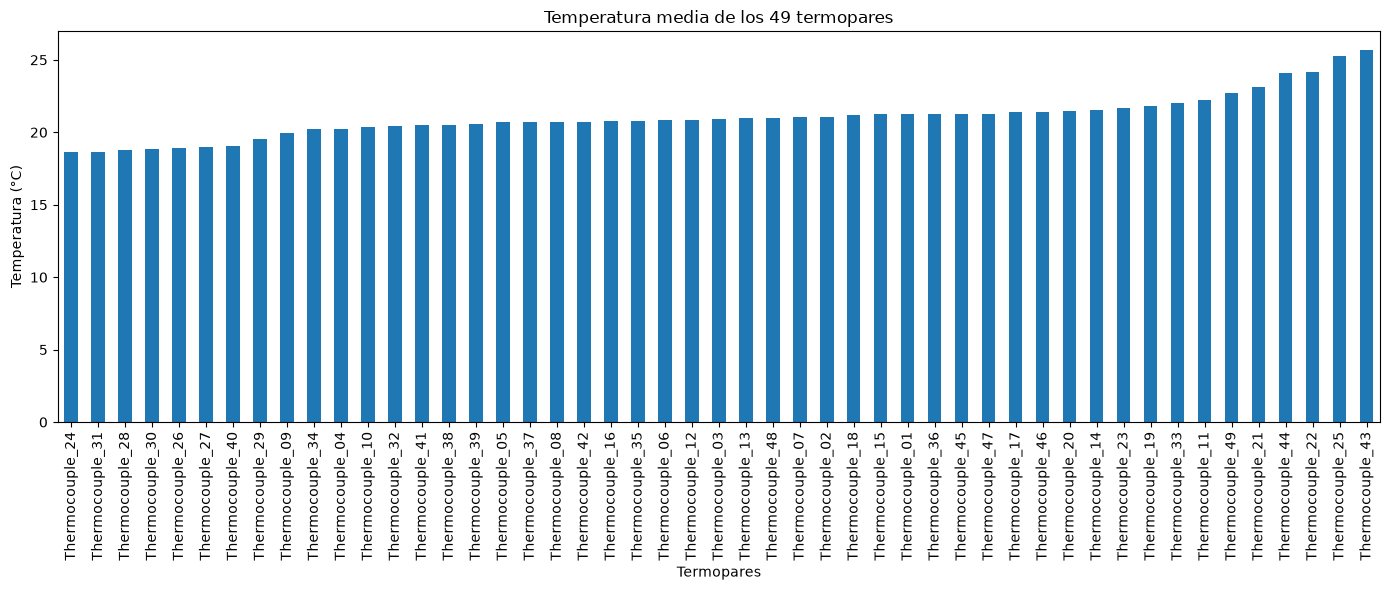

In [30]:
# Representamos la temperatura media de cada termopar

temperaturas_medias.sort_values().plot(
    kind="bar",
    figsize=(14, 6),
    title="Temperatura media de los 49 termopares",
    ylabel="Temperatura (°C)",
    xlabel="Termopares"
)

plt.tight_layout()
plt.show()

In [32]:
# Calculamos la desviación estándar de cada termopar

variabilidad_temperaturas = subset_termopares.std()

print(variabilidad_temperaturas.sort_values(ascending=False))

Thermocouple_44   7.015
Thermocouple_43   6.447
Thermocouple_25   5.285
Thermocouple_32   4.185
Thermocouple_22   3.586
Thermocouple_11   2.631
Thermocouple_24   2.322
Thermocouple_21   2.293
Thermocouple_49   2.148
Thermocouple_48   2.103
Thermocouple_15   1.797
Thermocouple_19   1.738
Thermocouple_16   1.724
Thermocouple_23   1.681
Thermocouple_47   1.642
Thermocouple_08   1.609
Thermocouple_14   1.576
Thermocouple_36   1.561
Thermocouple_18   1.461
Thermocouple_46   1.417
Thermocouple_33   1.416
Thermocouple_20   1.402
Thermocouple_03   1.354
Thermocouple_02   1.346
Thermocouple_01   1.280
Thermocouple_12   1.271
Thermocouple_07   1.256
Thermocouple_17   1.232
Thermocouple_13   1.201
Thermocouple_42   1.167
Thermocouple_45   1.156
Thermocouple_35   1.126
Thermocouple_10   1.072
Thermocouple_40   1.056
Thermocouple_05   1.055
Thermocouple_04   0.986
Thermocouple_28   0.978
Thermocouple_29   0.973
Thermocouple_06   0.920
Thermocouple_27   0.915
Thermocouple_26   0.914
Thermocouple_41 

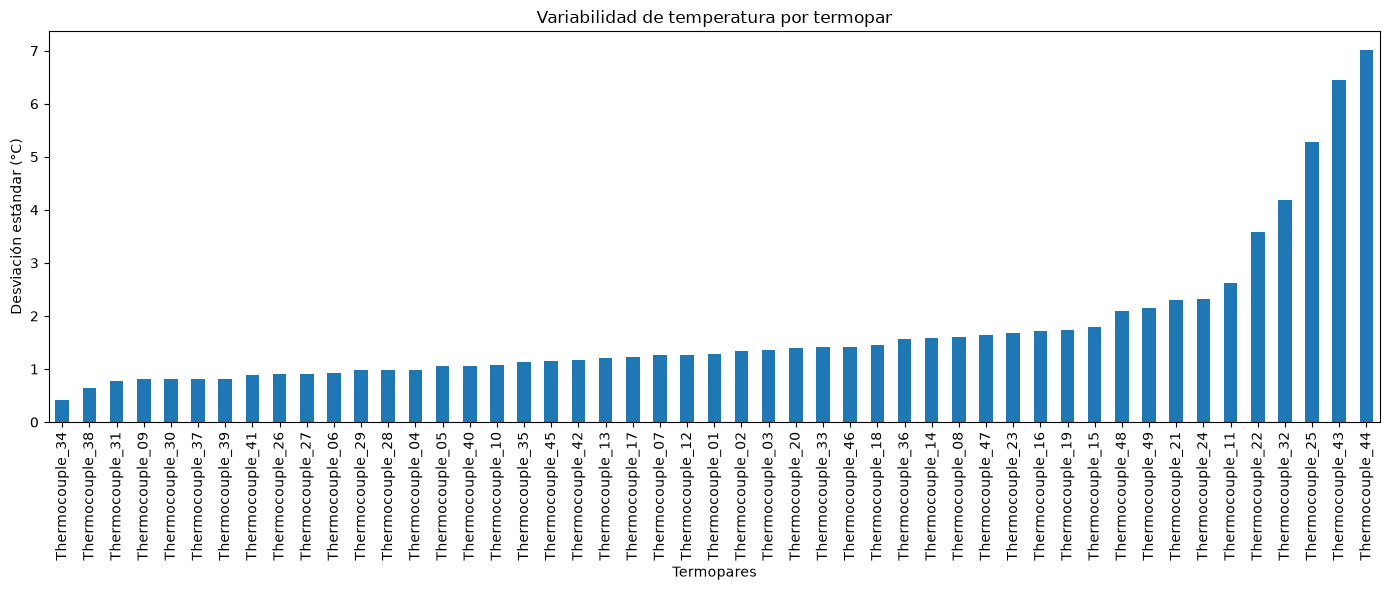

In [33]:
# Representamos la variabilidad de cada termopar

variabilidad_temperaturas.sort_values().plot(
    kind="bar",
    figsize=(14, 6),
    title="Variabilidad de temperatura por termopar",
    ylabel="Desviación estándar (°C)",
    xlabel="Termopares"
)

plt.tight_layout()
plt.show()

In [34]:
# Calculamos la temperatura máxima registrada por cada termopar

temperaturas_maximas = subset_termopares.max()

print(temperaturas_maximas.sort_values(ascending=False))

Thermocouple_44   56.900
Thermocouple_43   42.900
Thermocouple_25   36.900
Thermocouple_22   36.400
Thermocouple_32   35.400
Thermocouple_11   30.200
Thermocouple_21   28.900
Thermocouple_23   27.600
Thermocouple_49   26.300
Thermocouple_24   25.100
Thermocouple_16   24.900
Thermocouple_14   24.700
Thermocouple_47   24.600
Thermocouple_48   24.600
Thermocouple_19   24.600
Thermocouple_33   24.500
Thermocouple_36   24.400
Thermocouple_17   24.400
Thermocouple_08   24.300
Thermocouple_01   24.200
Thermocouple_15   24.200
Thermocouple_46   24.100
Thermocouple_07   24.100
Thermocouple_02   24.000
Thermocouple_12   24.000
Thermocouple_20   23.900
Thermocouple_03   23.800
Thermocouple_18   23.700
Thermocouple_13   23.100
Thermocouple_45   23.100
Thermocouple_06   22.900
Thermocouple_05   22.900
Thermocouple_35   22.800
Thermocouple_10   22.800
Thermocouple_42   22.600
Thermocouple_41   22.400
Thermocouple_04   22.400
Thermocouple_39   22.100
Thermocouple_37   21.900
Thermocouple_09   21.900


In [35]:
# Reunimos las principales estadísticas de temperatura

resumen_termopares = pd.DataFrame({
    "Temperatura_media": temperaturas_medias,
    "Temperatura_maxima": temperaturas_maximas,
    "Desviacion_estandar": variabilidad_temperaturas
})

print(resumen_termopares.sort_values(
    "Temperatura_maxima",
    ascending=False
))

                 Temperatura_media  Temperatura_maxima  Desviacion_estandar
Thermocouple_44             24.095              56.900                7.015
Thermocouple_43             25.684              42.900                6.447
Thermocouple_25             25.243              36.900                5.285
Thermocouple_22             24.159              36.400                3.586
Thermocouple_32             20.406              35.400                4.185
Thermocouple_11             22.229              30.200                2.631
Thermocouple_21             23.159              28.900                2.293
Thermocouple_23             21.677              27.600                1.681
Thermocouple_49             22.735              26.300                2.148
Thermocouple_24             18.624              25.100                2.322
Thermocouple_16             20.764              24.900                1.724
Thermocouple_14             21.545              24.700                1.576
Thermocouple

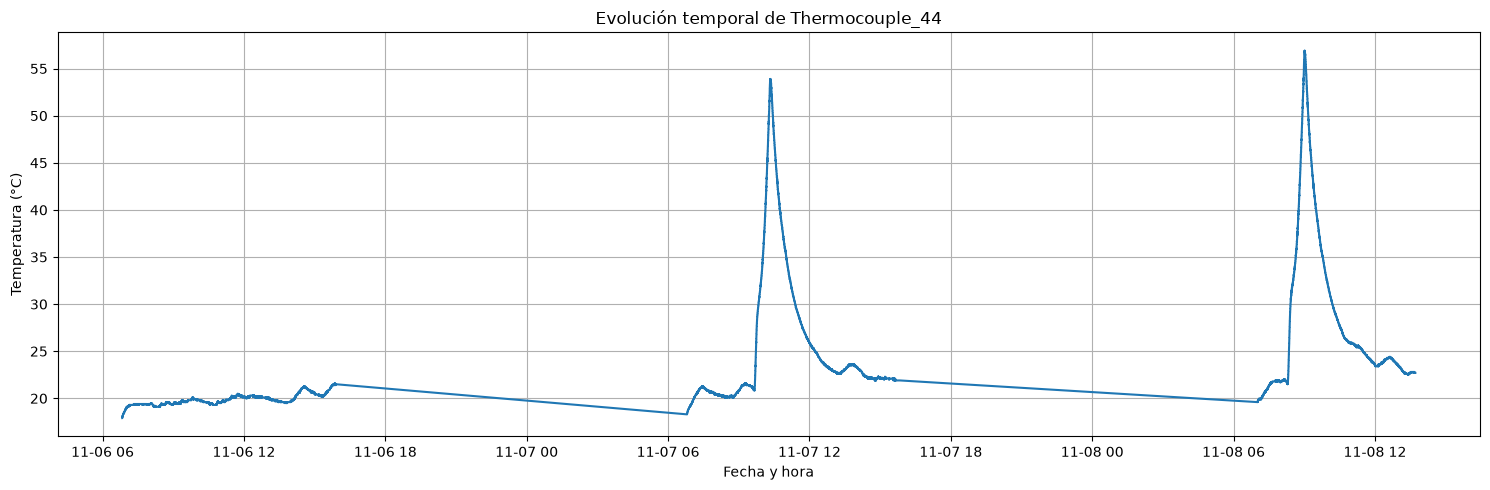

In [36]:
# Representamos la evolución temporal de Thermocouple_44

plt.figure(figsize=(15, 5))

plt.plot(
    sensores["Date"],
    sensores["Thermocouple_44"]
)

plt.title("Evolución temporal de Thermocouple_44")
plt.xlabel("Fecha y hora")
plt.ylabel("Temperatura (°C)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [37]:
# Localizamos los registros con las temperaturas máximas

indices_maximos = sensores["Thermocouple_44"].nlargest(5).index

print(
    sensores.loc[
        indices_maximos,
        ["Date", "Thermocouple_44"]
    ]
)

                     Date  Thermocouple_44
72469 2024-11-08 09:00:43           56.900
72470 2024-11-08 09:00:44           56.900
72471 2024-11-08 09:00:45           56.900
72472 2024-11-08 09:00:46           56.900
72473 2024-11-08 09:00:47           56.900


In [38]:
# Identificamos la temperatura máxima de cada día

sensores["Dia"] = sensores["Date"].dt.date

indices_maximos_dia = sensores.groupby("Dia")["Thermocouple_44"].idxmax()

maximos_diarios = sensores.loc[
    indices_maximos_dia,
    ["Date", "Thermocouple_44"]
]

print(maximos_diarios)

                     Date  Thermocouple_44
32444 2024-11-06 15:50:54           21.600
45309 2024-11-07 10:19:57           53.900
72469 2024-11-08 09:00:43           56.900


In [39]:
# Calculamos las estadísticas principales de los sensores IDS

resumen_ids = subset_ids.agg(["min", "max", "mean", "std"]).T

# Calculamos el rango de variación de cada sensor
resumen_ids["Rango"] = resumen_ids["max"] - resumen_ids["min"]

print(resumen_ids.sort_values("Rango", ascending=False))

             min       max      mean    std   Rango
Bar_05 63110.070 63281.630 63205.964 67.082 171.560
Bar_01 58820.200 58967.590 58904.206 37.532 147.390
Bar_09 59833.280 59937.100 59887.312 32.104 103.820
Bar_02 61091.540 61186.390 61143.249 27.039  94.850
Bar_04 58359.460 58433.040 58399.072 19.914  73.580
Bar_03 60251.140 60314.070 60284.007 19.100  62.930
Bar_08 60650.430 60692.010 60671.224 11.746  41.580
Bar_14 58578.630 58616.300 58600.604  9.335  37.670
Bar_06 61862.340 61892.010 61876.094  9.010  29.670
Bar_11 58119.480 58146.140 58131.446  7.934  26.660
Bar_07 58723.050 58749.220 58737.599  7.127  26.170
Bar_12 59687.740 59705.260 59698.170  4.818  17.520
Bar_13 60960.190 60970.700 60965.345  2.964  10.510
Bar_10 61353.880 61362.230 61358.667  1.969   8.350


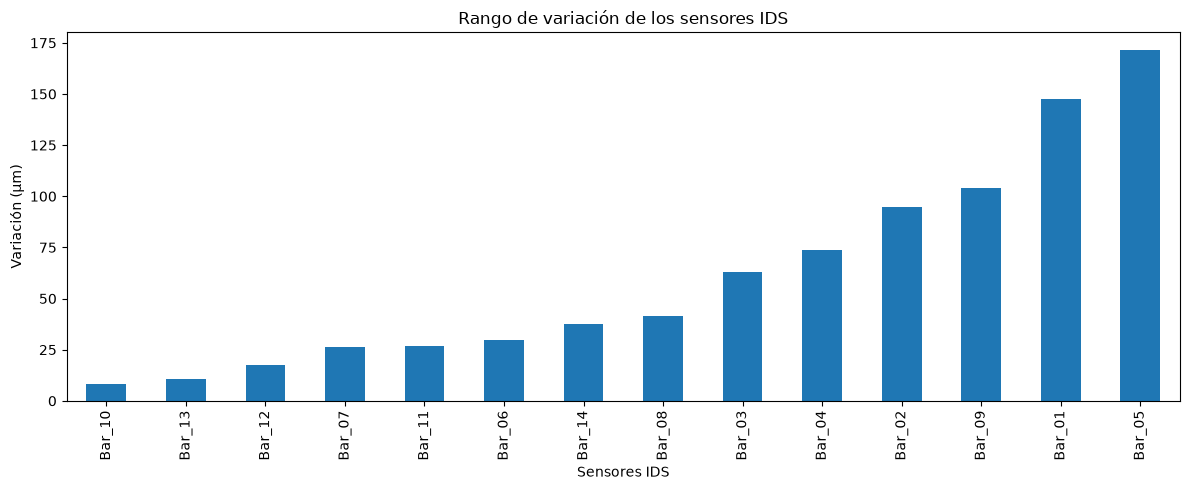

In [40]:
# Representamos el rango de variación de cada sensor IDS

resumen_ids["Rango"].sort_values().plot(
    kind="bar",
    figsize=(12, 5),
    title="Rango de variación de los sensores IDS",
    ylabel="Variación (µm)",
    xlabel="Sensores IDS"
)

plt.tight_layout()
plt.show()